# Приближенный вариационный вывод
Задача: выявить распределение (степень неопределенности обусловнное неучтенными факторами, такими как конкуренты, акции и пр) средних продаж для каждого среза цены

Метод решения:
1. Создаем симуляцию с зараннее заданными параметрами (скрытыми переменными)
2. По результатам симуляции и определеяем эти параметры (скрытыие переменные)
3. Если удастся получить параметры симуляции близкие к заданным, мы можем рассчитывать на то, что в реальных данных определяемые нами скрытые параметры будут также близки к фактическим

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.optim as optim
from scipy.stats import gamma
from torch.distributions import Gamma, Poisson
from scipy.optimize import curve_fit

Симуляция стационарных продаж ($\lambda$ = const для каждого среза цены)

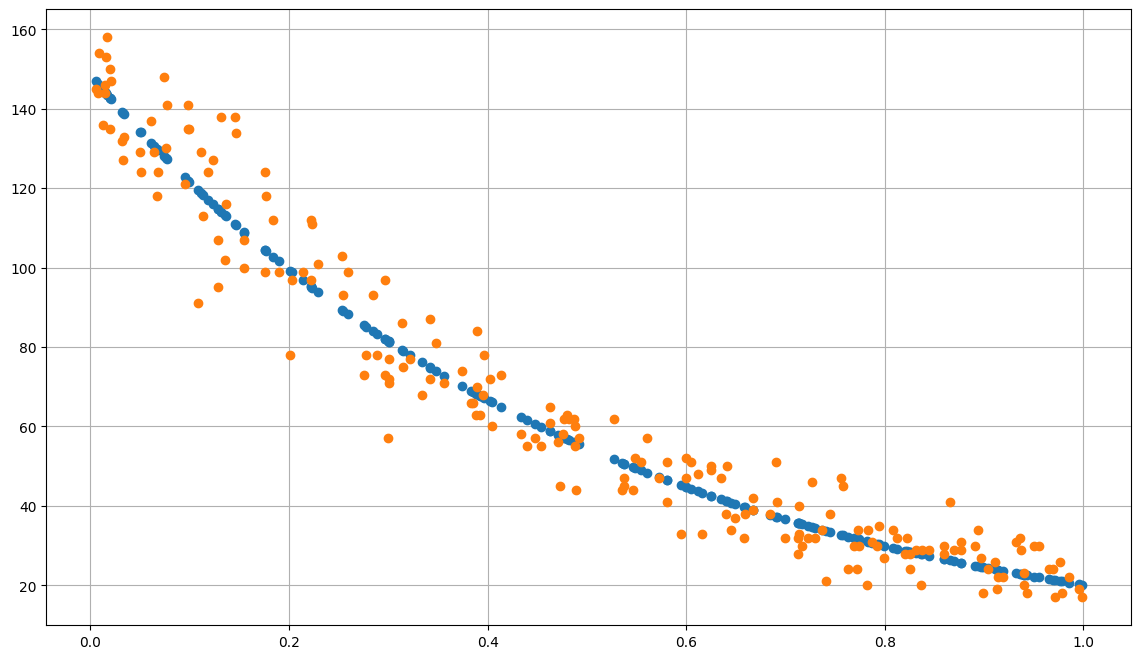

In [2]:
fig, ax = plt.subplots(figsize=(14, 8))
N = 200
p = np.random.rand(N)
a = -2
b = 5
t = np.exp(a * p + b)
order = np.random.poisson(t)
plt.plot(p, t, "o")
plt.plot(p, order, "o")
plt.grid(True)


Симуляция нестационарных продаж. Тепреь $\lambda$ (средние продажи) приходит из Гамма распределения

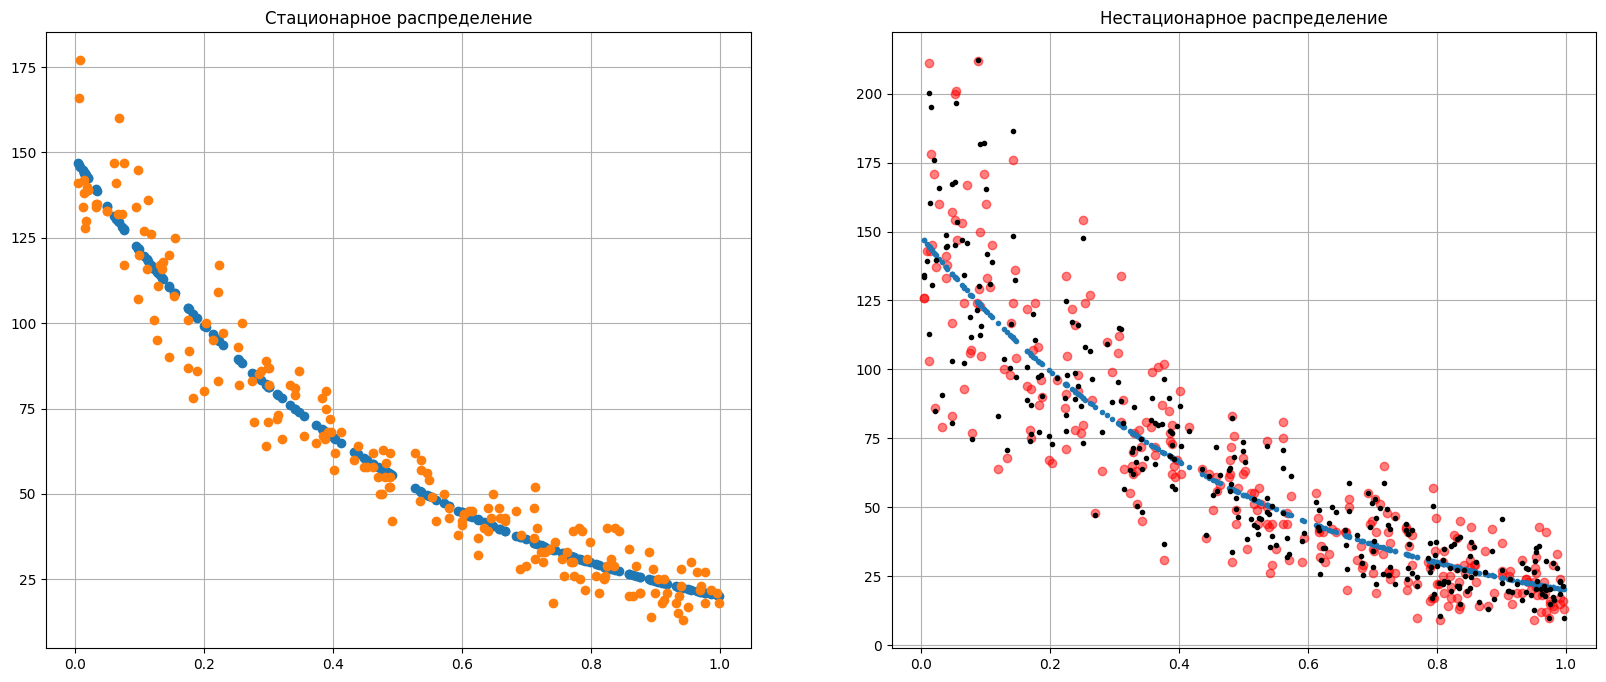

In [3]:
W0, W1, W2 = 1, 0.5, 0.05


def get_data(a=-2, b=5, w0=W0, w1=W1, w2=W2, N=300):
    """ """
    p = np.random.rand(N)
    E = np.exp(a * p + b)
    D = w0 + E * w1 + E**2 * w2
    shape = E**2 / D
    scale = D / E
    g = np.random.gamma(shape, scale)
    pois = np.random.poisson(g)
    return pois, g, E, p, shape, scale, D


fig, ax = plt.subplots(1, 2, figsize=(20, 8))
t = np.exp(a * p + b)
order = np.random.poisson(t)
ax[0].plot(p, t, "o")
ax[0].plot(p, order, "o")
ax[0].grid(True)
ax[0].set_title("Стационарное распределение")
poes, t, e, p, shape, scale, d = get_data()
# plt.plot(p,t,'.')
# plt.plot(p,e,'.')
ax[1].plot(p, poes, "or", alpha=0.5)
ax[1].plot(p, e, ".")
ax[1].plot(p, t, ".k")
ax[1].set_title("Нестационарное распределение")
ax[1].grid(True);


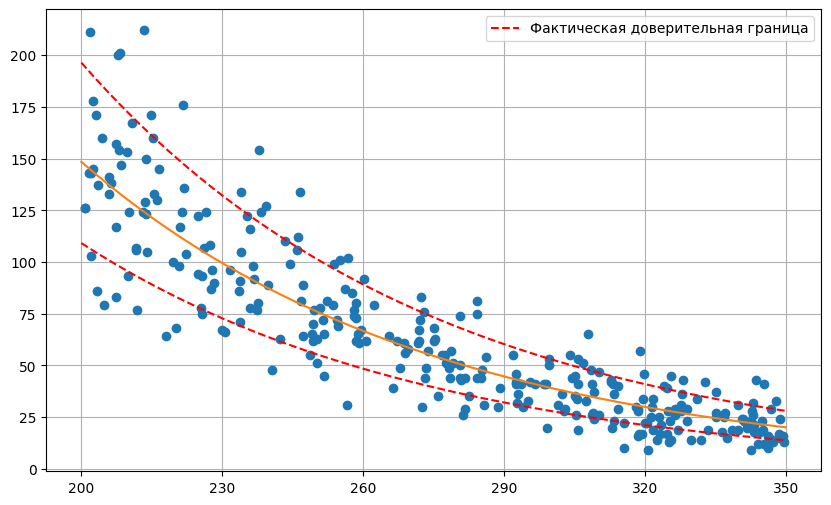

In [4]:
def get_params(Y, ww0, ww1, ww2):
    t = (ww0 + ww1 * Y + ww2 * Y**2) / Y
    k = Y**2 / (ww0 + ww1 * Y + ww2 * Y**2)
    return t, k


x = np.linspace(0, 1)
Y = np.exp(-2 * x + 5)
t, k =  get_params(Y, W0, W1, W2)
y_up = np.zeros(50)
y_down = np.zeros(50)
y_up_real = np.zeros(50)
y_down_real = np.zeros(50)
for i in range(50):
    #p80 = gamma.ppf([0.1, 0.5, 0.9], a=k, scale=t)
    #f = np.diff(p80)
    #y_up[i] = Y[i] + f[1]
    #y_down[i] = Y[i] - f[0]

    t_real, k_real = get_params(Y[i], W0, W1, W2)
    p80_real = gamma.ppf([0.1, 0.5, 0.9], a=k_real, scale=t_real)
    f_real = np.diff(p80_real)
    y_up_real[i] = Y[i] + f_real[1]
    y_down_real[i] = Y[i] - f_real[0]

plt.figure(figsize=(10, 6))
plt.plot(p, poes, "o")
plt.plot(x, Y)
# plt.plot( x, y_up, "*-k", linewidth=3, label="Доверительная граница полученная в результате оптимизации")
# plt.plot(x, y_down, "*-k", linewidth=3)
plt.plot(x, y_up_real, "--r", label="Фактическая доверительная граница")
plt.plot(x, y_down_real, "--r")
plt.grid(True)
plt.legend()
plt.xticks([0, 0.2, 0.4, 0.6, 0.8, 1], [200, 230, 260, 290, 320, 350]);

Пусть $\lambda$ имеет распределение
$$ p(\lambda|k,\theta) = Gamma(k,\theta)$$
Мат ожидание и дисперсия выражается через $k$, $\theta$
$$ \mathbb E[\lambda] = k\theta, \mathbb D[\lambda] = k\theta^2 $$
$$ k = \frac{\mathbb E[\lambda]}{\mathbb{D[\lambda]}} ,  \theta = \frac{\mathbb{D[\lambda]}}{\mathbb E^2[\lambda]} \tag{1} $$




Полагая, что $\mathbb E[\lambda]$ мы оценили моделью, введем зависимость дисперсии данных от $\lambda$
$$ \mathbb D[\lambda] = w_0 + w_1\lambda + w_2\lambda^2 $$
Выражение (1) с учетом последнего
$$ k = \frac{\mathbb E[\lambda]}{ w_0 + w_1\lambda + w_2\lambda^2} ,  \theta = \frac{ w_0 + w_1\lambda+ w_2\lambda^2}{\mathbb E^2[\lambda]} \tag{2} $$
Тогда, Байесовский вывод

$$p(k,\theta|o) = \frac{p(o|\lambda)p(\lambda|k,\theta)p(w_0)p(w_1)p(w_2)}{\int\int p(o|\lambda)p(\lambda|k,\theta)p(w_0)p(w_1)p(w_2)dw_0 dw_1 dw_2}$$

## ELBO
$$ ELBO = \ln p(o|\lambda) + \ln p(\lambda|k,\theta) + \ln p(w_0)+ \ln p(w_1) + \ln p(w_2) +H[q(w_0)] + H[q[w_1)] + H[q[w_2)]+ H[q(\lambda)]$$
$$ \ln p(\lambda|k,\theta) = \sum_i \ln Gamma(\lambda_i|k_i,\theta_i) $$

In [5]:
# get_data(a=-2,b=3,w0=1,w1=0.5,w2 = 0.05,N=300)
poes, t, e, p, shape, scale, d = get_data(a=-2, b=5, N=200)

In [6]:
def func(price, a, b):
    return np.exp(a * price +b)

popt, pcov = curve_fit(func, p, poes)


E = func(p, popt[0], popt[1])

Для нахождения параметров $w_0$ и $w_1$ применяестя приближенный байесовский вывод. В этом выводе мы оптимизируем нижнюю границу доказательства (Evidence lower bound) [ELBO](https://en.wikipedia.org/wiki/Evidence_lower_bound)

Задаем начальные значения для всех искомых параметров

In [7]:
w0_mu = torch.tensor(1.0, dtype=torch.float, requires_grad=True)
w0_scale = torch.tensor(1.0, dtype=torch.float, requires_grad=True)

w1_mu = torch.tensor(1.0, dtype=torch.float, requires_grad=True)
w1_scale = torch.tensor(1.0, dtype=torch.float, requires_grad=True)


w2_mu = torch.tensor(0.0, dtype=torch.float, requires_grad=True)
w2_scale = torch.tensor(0.0, dtype=torch.float, requires_grad=True)

# Параметры для оптимизации
params = [w0_mu, w0_scale, w1_mu, w1_scale, w2_mu, w2_scale]

E = torch.tensor(E)

data = torch.tensor(poes)
mod_exp = torch.tensor(e, dtype=torch.float)


def get_variational_distributions(E):
    # Вариационное распределение для w0

    w0_mu_e = torch.exp(w0_mu)
    w0_scale_e = torch.exp(w0_scale)
    # print(w0_mu_e,w0_scale_e)
    q_w0 = Gamma(w0_mu_e, 1.0 / w0_scale_e)
    w0 = w0_mu_e * w0_scale_e

    w1_mu_e = torch.exp(w1_mu)
    w1_scale_e = torch.exp(w1_scale)
    q_w1 = Gamma(w1_mu_e, 1.0 / w1_scale_e)
    w1 = w1_mu_e * w1_scale_e

    w2_mu_e = torch.exp(w2_mu)
    w2_scale_e = torch.exp(w2_scale)
    q_w2 = Gamma(w2_mu_e, 1.0 / w2_scale_e)
    w2 = w2_mu_e * w2_scale_e

    # Вариационные параметры для lambda_i
    k = E**2 / (w0 + w1 * E + w2 * E**2)
    theta = (w0 + w1 * E + w2 * E**2) / E

    q_lambda = Gamma(k, 1.0 / theta)

    return q_w0, q_w1, q_w2, q_lambda, w0, w1, w2


## Задание
1. Найти параметры $ k, \theta$
2. Построить доверительный интервал для оценки матожидания спроса найденный из вариационного вывода и сравнить его с фактическим доверительным интервалом
3. Написать СВОИ выводы

Оценки коэффициентов дисперсии:
w0 = 1.2087 ± 0.8070 (истинное значение: 1)
w1 = 0.4819 ± 0.3051 (истинное значение: 0.5)
w2 = 0.0589 ± 0.0156 (истинное значение: 0.05)

Параметры Gamma-распределения для срезов цены:
k: от 11.7796 до 16.0947
theta: от 1.7623 до 9.3387


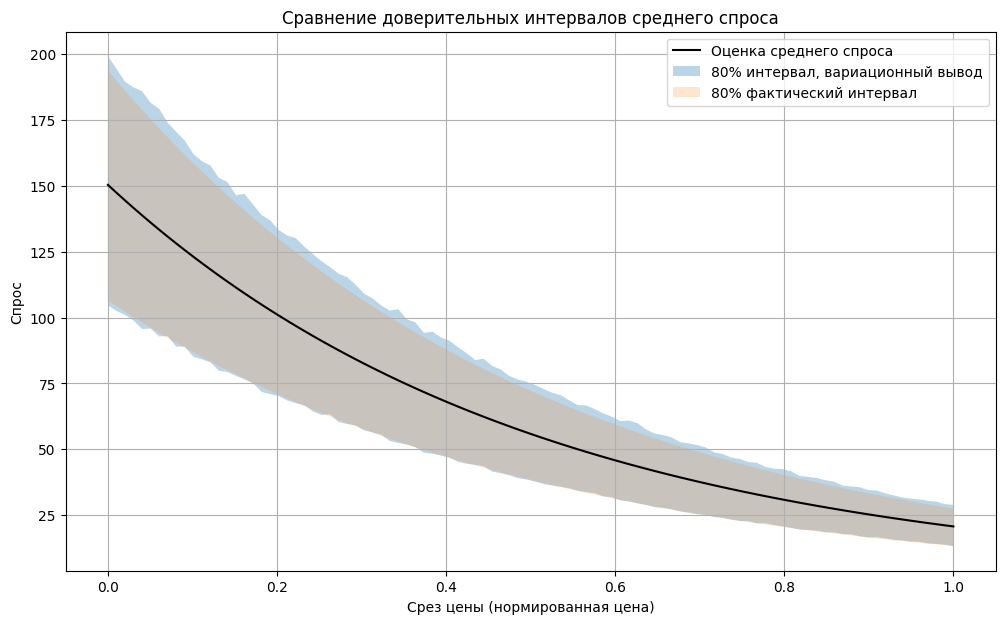

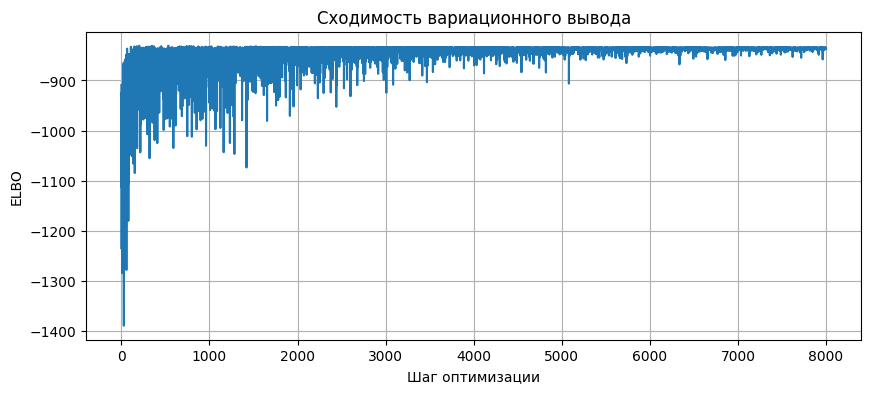

In [8]:
from torch.distributions import NegativeBinomial

torch.manual_seed(42)
np.random.seed(42)

E_fit = E.to(dtype=torch.float32)
observed = data.to(dtype=torch.float32)

priors = [
    Gamma(torch.tensor(2.0), torch.tensor(2.0)),   # prior mean = 1.0
    Gamma(torch.tensor(2.0), torch.tensor(4.0)),   # prior mean = 0.5
    Gamma(torch.tensor(2.0), torch.tensor(40.0)),  # prior mean = 0.05
]

optimizer = optim.Adam(params, lr=0.006)
n_steps = 8000
elbo_history = []

for step in range(n_steps):
    optimizer.zero_grad()

    q_w0, q_w1, q_w2, _, _, _, _ = get_variational_distributions(E_fit)
    q_ws = [q_w0, q_w1, q_w2]
    w_samples = [q.rsample() for q in q_ws]

    w0_sample, w1_sample, w2_sample = w_samples
    variance = w0_sample + w1_sample * E_fit + w2_sample * E_fit**2
    k_sample = E_fit**2 / variance
    theta_sample = variance / E_fit

    # Маргинальное распределение наблюдений:
    # data ~ NegativeBinomial(k, probs), где mean = k * theta = E_fit.
    probs = theta_sample / (1.0 + theta_sample)
    log_likelihood = NegativeBinomial(
        total_count=k_sample, probs=probs
    ).log_prob(observed).sum()

    log_prior = sum(prior.log_prob(w) for prior, w in zip(priors, w_samples))
    log_q = sum(q.log_prob(w) for q, w in zip(q_ws, w_samples))

    elbo = log_likelihood + log_prior - log_q
    (-elbo).backward()
    torch.nn.utils.clip_grad_norm_(params, max_norm=10.0)
    optimizer.step()

    elbo_history.append(elbo.detach().item())

# Параметры вариационных Gamma-распределений для w0, w1, w2.
with torch.no_grad():
    q_w0, q_w1, q_w2, _, _, _, _ = get_variational_distributions(E_fit)
    q_ws = [q_w0, q_w1, q_w2]

    w_means = [
        (torch.exp(mu) * torch.exp(scale)).item()
        for mu, scale in [
            (w0_mu, w0_scale),
            (w1_mu, w1_scale),
            (w2_mu, w2_scale),
        ]
    ]
    w_stds = [q.stddev.item() for q in q_ws]

w0_est, w1_est, w2_est = w_means
print("Оценки коэффициентов дисперсии:")
for name, estimate, std, true_value in zip(
    ["w0", "w1", "w2"], w_means, w_stds, [W0, W1, W2]
):
    print(f"{name} = {estimate:.4f} ± {std:.4f} (истинное значение: {true_value})")

# Строим сетку значений цены и соответствующие оценки среднего спроса.
price_grid = np.linspace(0, 1, 100)
E_grid = torch.tensor(
    func(price_grid, popt[0], popt[1]), dtype=torch.float32
)
E_true_grid = np.exp(a * price_grid + b)

# Получаем интервалы из вариационного апостериорного распределения:
# учитываем неопределенность и в w0,w1,w2, и в lambda.
n_posterior_samples = 3000
with torch.no_grad():
    w_draws = [q.sample((n_posterior_samples,)) for q in q_ws]
    variance_draws = (
        w_draws[0][:, None]
        + w_draws[1][:, None] * E_grid[None, :]
        + w_draws[2][:, None] * E_grid[None, :]**2
    )
    k_draws = E_grid[None, :]**2 / variance_draws
    theta_draws = variance_draws / E_grid[None, :]
    lambda_draws = Gamma(
        k_draws, 1.0 / theta_draws
    ).sample()

lower_vi = torch.quantile(lambda_draws, 0.10, dim=0).cpu().numpy()
upper_vi = torch.quantile(lambda_draws, 0.90, dim=0).cpu().numpy()

# Фактический 80%-й интервал, рассчитанный по параметрам исходной симуляции.
true_variance = W0 + W1 * E_true_grid + W2 * E_true_grid**2
true_k = E_true_grid**2 / true_variance
true_theta = true_variance / E_true_grid
lower_true = gamma.ppf(0.10, a=true_k, scale=true_theta)
upper_true = gamma.ppf(0.90, a=true_k, scale=true_theta)

# Параметры k и theta, оцененные вариационным выводом, для каждого среза цены.
variance_est = w0_est + w1_est * E_grid + w2_est * E_grid**2
k_est = E_grid**2 / variance_est
theta_est = variance_est / E_grid

print("\nПараметры Gamma-распределения для срезов цены:")
print(f"k: от {k_est.min().item():.4f} до {k_est.max().item():.4f}")
print(f"theta: от {theta_est.min().item():.4f} до {theta_est.max().item():.4f}")

plt.figure(figsize=(12, 7))
plt.plot(price_grid, E_grid.cpu().numpy(), color="black",
         label="Оценка среднего спроса")
plt.fill_between(price_grid, lower_vi, upper_vi, alpha=0.30,
                 label="80% интервал, вариационный вывод")
plt.fill_between(price_grid, lower_true, upper_true, alpha=0.20,
                 label="80% фактический интервал")
plt.xlabel("Срез цены (нормированная цена)")
plt.ylabel("Спрос")
plt.title("Сравнение доверительных интервалов среднего спроса")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(elbo_history)
plt.xlabel("Шаг оптимизации")
plt.ylabel("ELBO")
plt.title("Сходимость вариационного вывода")
plt.grid(True)
plt.show()

## Выводы
На основе коэффциентов w были рассчитаны параметры гамма-распределения: k изменяется от 11.7796 до 16.0947, а theta от 1.7623 до 9.3387

Доверительный интервал вариационного вывода и  фактический доверительный интвервал изменяются почти одинаково, но фактический немного шире, что говорит о хорошем приближении доверительного интервала вариационного вывода

График сходимости вариационного вывода резко увеличивается в начале, но к концу уже полностью стабилизируется за счет достижения устойчивого состояния
